<a href="https://colab.research.google.com/github/Hefot-Ahmed/Machine-Learning-/blob/main/Titanic_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("train.csv")

In [3]:
train.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [4]:
train.shape

(891, 12)

In [5]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [6]:
train.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [8]:
test = pd.read_csv("test-selected-columns.csv")

In [9]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN


In [10]:
test.shape

(418, 10)

In [11]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [12]:
train.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [13]:
train["Age"].median()

28.0

In [14]:
train_clean = train.copy()
test_clean = test.copy()

In [15]:
train_clean["Age"] = train_clean["Age"].fillna(train_clean["Age"].median())

In [16]:
train_clean["Age"].isnull().sum()

np.int64(0)

In [17]:
train_clean["Embarked"].value_counts()

,count
Embarked,
S,644
C,168
Q,77


In [18]:
train_clean["Embarked"].mode()[0]

'S'

In [19]:
train_clean["Embarked"] = train_clean["Embarked"].fillna(train_clean["Embarked"].mode()[0])

In [20]:
train_clean["Embarked"].isnull().sum()

np.int64(0)

In [21]:
train_clean = train_clean.drop(columns=["Cabin"])

In [22]:
train_clean.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [23]:
train_clean.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [24]:
test_clean.isnull().sum()

,0
PassengerId,0
Pclass,0
Name,0
Sex,0
Age,86
SibSp,0
Parch,0
Ticket,0
Fare,1
Cabin,327


In [25]:
age_median = train["Age"].median()

In [26]:
test_clean["Age"] = test_clean["Age"].fillna(age_median)

In [27]:
test_clean["Fare"].isnull().sum()

np.int64(1)

In [28]:
fare_median = train["Fare"].median()

In [29]:
test_clean["Fare"] = test_clean["Fare"].fillna(fare_median)

In [30]:
test_clean = test_clean.drop(columns=["Cabin"])

In [31]:
test_clean.isnull().sum()

,0
PassengerId,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [32]:
train_clean.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [33]:
train_clean["Survived"].value_counts()

,count
Survived,
0,549
1,342


In [34]:
train_clean["Survived"].value_counts(normalize=True) * 100

,proportion
Survived,
0,61.616162
1,38.383838


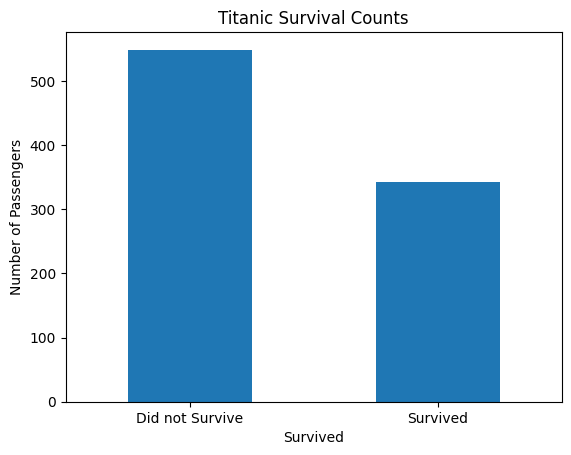

In [35]:
train_clean["Survived"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.title("Titanic Survival Counts")
plt.xticks([0,1], ["Did not Survive", "Survived"], rotation=0)

plt.show()

In [36]:
pd.crosstab(train_clean["Sex"], train_clean["Survived"])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [37]:
train_clean.groupby("Sex")["Survived"].mean()

,Survived
Sex,
female,0.742038
male,0.188908


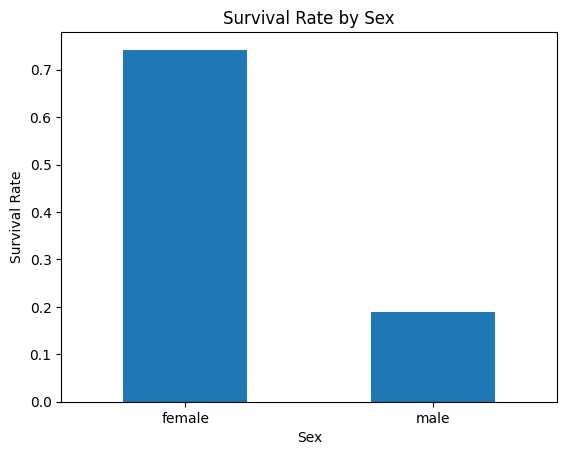

In [38]:
train_clean.groupby("Sex")["Survived"].mean().plot(kind="bar")

plt.ylabel("Survival Rate")
plt.title("Survival Rate by Sex")
plt.xticks(rotation=0)
plt.show()

In [39]:
train_clean.groupby("Pclass")["Survived"].mean()

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


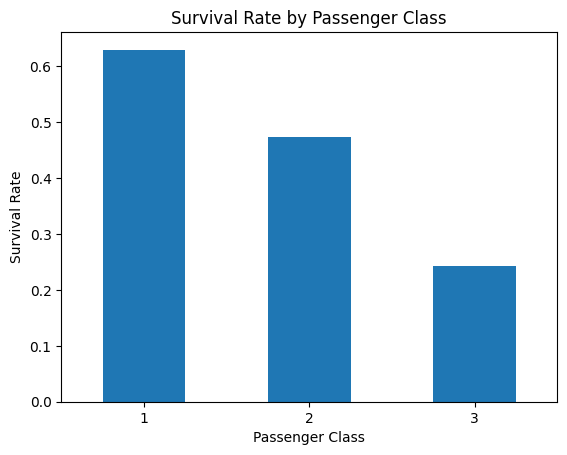

In [40]:
train_clean.groupby("Pclass")["Survived"].mean().plot(kind="bar")

plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.title("Survival Rate by Passenger Class")
plt.xticks(rotation=0)

plt.show()

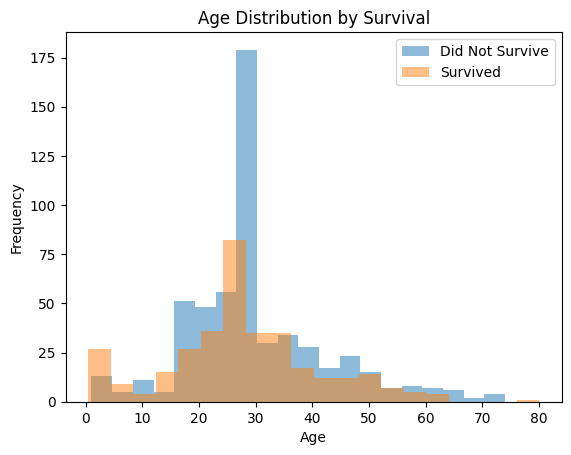

In [41]:
train_clean[train_clean["Survived"] == 0]["Age"].plot(
    kind="hist",
    alpha=0.5,
    bins=20,
    label="Did Not Survive"
)

train_clean[train_clean["Survived"] == 1]["Age"].plot(
    kind="hist",
    alpha=0.5,
    bins=20,
    label="Survived"
)

plt.xlabel("Age")
plt.title("Age Distribution by Survival")
plt.legend()

plt.show()

In [42]:
train_clean["AgeGroup"] = pd.cut(
    train_clean["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"]
)

In [43]:
train_clean.groupby("AgeGroup", observed=False)["Survived"].mean()

,Survived
AgeGroup,
Child,0.579710
Teen,0.428571
Young Adult,0.353271
Adult,0.400000
Senior,0.227273


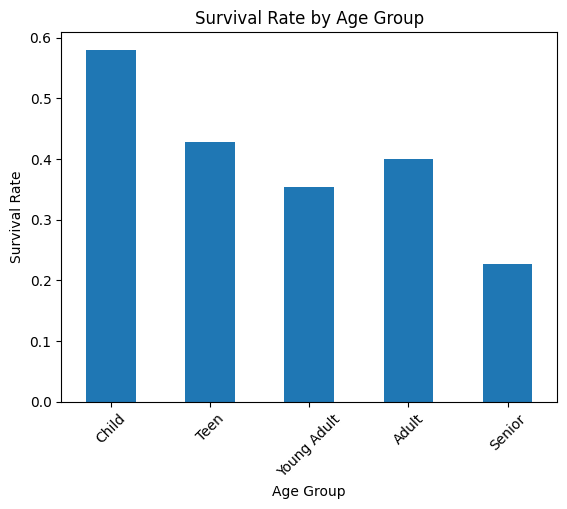

In [44]:
train_clean.groupby("AgeGroup", observed=False)["Survived"].mean().plot(
    kind="bar"
)

plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.title("Survival Rate by Age Group")
plt.xticks(rotation=45)

plt.show()

In [45]:
train_clean.groupby("Survived")["Fare"].mean()

,Fare
Survived,
0,22.117887
1,48.395408


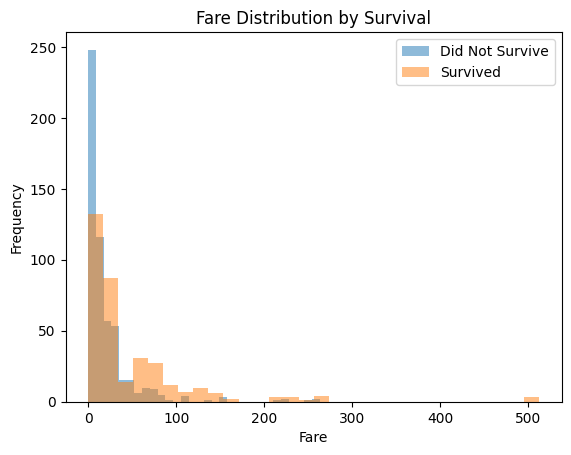

In [46]:
train_clean[train_clean["Survived"] == 0]["Fare"].plot(
    kind="hist",
    alpha=0.5,
    bins=30,
    label="Did Not Survive"
)

train_clean[train_clean["Survived"] == 1]["Fare"].plot(
    kind="hist",
    alpha=0.5,
    bins=30,
    label="Survived"
)

plt.xlabel("Fare")
plt.title("Fare Distribution by Survival")
plt.legend()

plt.show()

In [47]:
train_clean["FamilySize"] = (
    train_clean["SibSp"] +
    train_clean["Parch"] +
    1
)

In [48]:
train_clean.groupby("FamilySize")["Survived"].mean()

,Survived
FamilySize,
1,0.303538
2,0.552795
3,0.578431
4,0.724138
5,0.200000
6,0.136364
7,0.333333
8,0.000000
11,0.000000


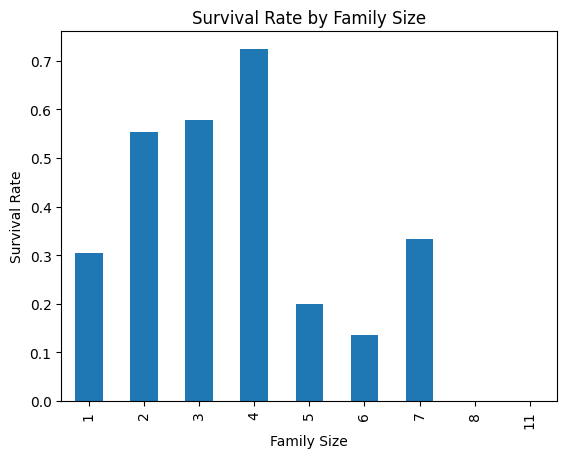

In [49]:
train_clean.groupby("FamilySize")["Survived"].mean().plot(kind="bar")

plt.xlabel("Family Size")
plt.ylabel("Survival Rate")
plt.title("Survival Rate by Family Size")

plt.show()

In [50]:
train_clean.groupby(["Sex", "Pclass"])["Survived"].mean()

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

In [51]:
train_clean.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,AgeGroup,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Young Adult,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,Adult,2
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Young Adult,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,Young Adult,2
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Young Adult,1


In [52]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize"
]

X = train_clean[features]

X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize
0,3,male,22.0,1,0,7.2500,S,2
1,1,female,38.0,1,0,71.2833,C,2
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,2
4,3,male,35.0,0,0,8.0500,S,1


In [53]:
y = train_clean["Survived"]
y.head()

,Survived
0,0
1,1
2,1
3,1
4,0


In [54]:
X.dtypes

,0
Pclass,int64
Sex,object
Age,float64
SibSp,int64
Parch,int64
Fare,float64
Embarked,object
FamilySize,int64


In [55]:
X = pd.get_dummies(
    X,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

X.head()

,Pclass,Age,SibSp,Parch,Fare,FamilySize,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,2,1,0,1
1,1,38.0,1,0,71.2833,2,0,0,0
2,3,26.0,0,0,7.9250,1,0,0,1
3,1,35.0,1,0,53.1000,2,0,0,1
4,3,35.0,0,0,8.0500,1,1,0,1


In [56]:
X.shape

(891, 9)

In [57]:
y.shape

(891,)

In [58]:
from sklearn.model_selection import train_test_split

In [59]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [60]:
X_train.shape

(712, 9)

In [61]:
X_val.shape

(179, 9)

In [62]:
y_train.shape

(712,)

In [63]:
y_val.shape

(179,)

In [64]:
X_train.head()

,Pclass,Age,SibSp,Parch,Fare,FamilySize,Sex_male,Embarked_Q,Embarked_S
692,3,28.0,0,0,56.4958,1,1,0,1
481,2,28.0,0,0,0.0000,1,1,0,1
527,1,28.0,0,0,221.7792,1,1,0,1
855,3,18.0,0,1,9.3500,2,0,0,1
801,2,31.0,1,1,26.2500,3,0,0,1


In [65]:
X_train.shape, X_val.shape

((712, 9), (179, 9))

In [66]:
from sklearn.linear_model import LogisticRegression

In [67]:
model = LogisticRegression(max_iter=1000)

In [68]:
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [69]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_[0]
})

coefficients.sort_values("Coefficient", ascending=False)

,Feature,Coefficient
7,Embarked_Q,0.280485
3,Parch,0.031273
4,Fare,0.002255
1,Age,-0.038585
5,FamilySize,-0.103902
2,SibSp,-0.141843
8,Embarked_S,-0.380996
0,Pclass,-1.091707
6,Sex_male,-2.559568


In [70]:
y_pred = model.predict(X_val)

In [71]:
y_pred[:20]

array([0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1])

In [72]:
comparison = pd.DataFrame({
    "Actual": y_val.values,
    "Predicted": y_pred
})

comparison.head(20)

,Actual,Predicted
0,0,0
1,0,0
2,1,0
3,0,0
4,1,1
5,1,0
6,1,1
7,0,0
8,0,0
9,0,0


In [73]:
from sklearn.metrics import accuracy_score

In [74]:
accuracy = accuracy_score(y_val, y_pred)

accuracy

0.8044692737430168

In [75]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_pred)

cm

array([[98, 12],
       [23, 46]])

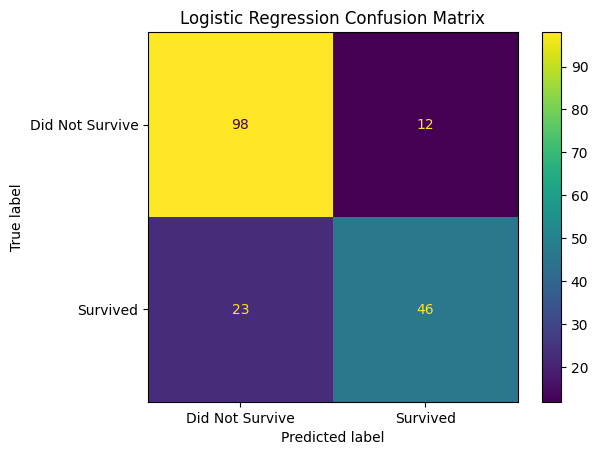

In [76]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["Did Not Survive", "Survived"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [77]:
from sklearn.metrics import precision_score

precision = precision_score(y_val, y_pred)

print(f"Precision: {precision:.2%}")

Precision: 79.31%


In [78]:
from sklearn.metrics import recall_score

recall = recall_score(y_val, y_pred)

print(f"Recall: {recall:.2%}")

Recall: 66.67%


In [79]:
from sklearn.metrics import f1_score

f1 = f1_score(y_val, y_pred)

print(f"F1 Score: {f1:.2%}")

F1 Score: 72.44%


In [80]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [81]:
from sklearn.ensemble import RandomForestClassifier

In [82]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [83]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [84]:
rf_pred = rf_model.predict(X_val)

In [85]:
rf_accuracy = accuracy_score(y_val, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy:.2%}")

Random Forest Accuracy: 81.01%


In [86]:
print(f"Logistic Regression: {accuracy:.2%}")
print(f"Random Forest:       {rf_accuracy:.2%}")

Logistic Regression: 80.45%
Random Forest:       81.01%


In [87]:
print("LOGISTIC REGRESSION")
print(classification_report(y_val, y_pred))

print("RANDOM FOREST")
print(classification_report(y_val, rf_pred))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

RANDOM FOREST
              precision    recall  f1-score   support

           0       0.83      0.86      0.85       110
           1       0.77      0.72      0.75        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179



In [88]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance

,Feature,Importance
4,Fare,0.273412
6,Sex_male,0.261490
1,Age,0.237682
0,Pclass,0.085662
5,FamilySize,0.050495
2,SibSp,0.033592
3,Parch,0.024457
8,Embarked_S,0.024002
7,Embarked_Q,0.009208


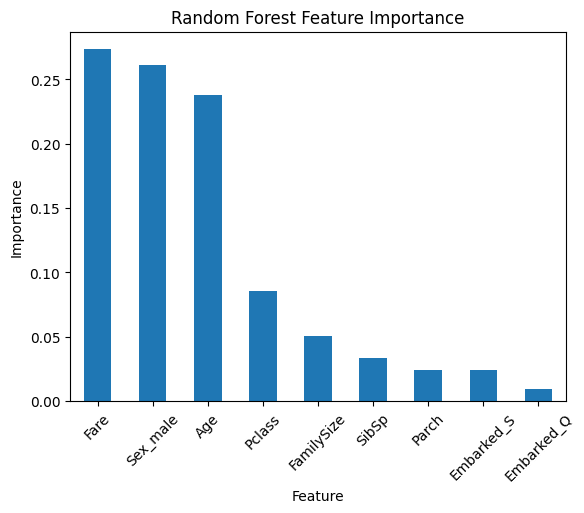

In [89]:
importance.set_index("Feature")["Importance"].plot(
    kind="bar"
)

plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.xticks(rotation=45)

plt.show()